AdaBoost Accuracy: 0.956140350877193

AdaBoost Estimator Weights:
[2.48490665 1.74396881 1.80718225 1.28495082 0.97874934 1.35521217
 1.16692674 1.09069352 0.99154396 0.90092444 0.90184652 0.98501919
 0.86557179 1.01864    0.93051689 0.95231468 0.72907064 0.71660375
 0.40009773 0.89115153 0.55852552 0.77724201 0.72514028 0.90220518
 1.04971263 0.67871304 0.58507121 0.84660992 0.7315246  0.93698378
 0.67532169 0.68123656 0.8386741  0.60228062 0.67780748 0.59895343
 0.52496287 0.62612329 0.67530747 0.66511821 0.7202675  0.85017877
 0.62379326 0.33939285 0.54112656 0.38860115 0.41353448 0.57944664
 0.53211487 0.60195494]


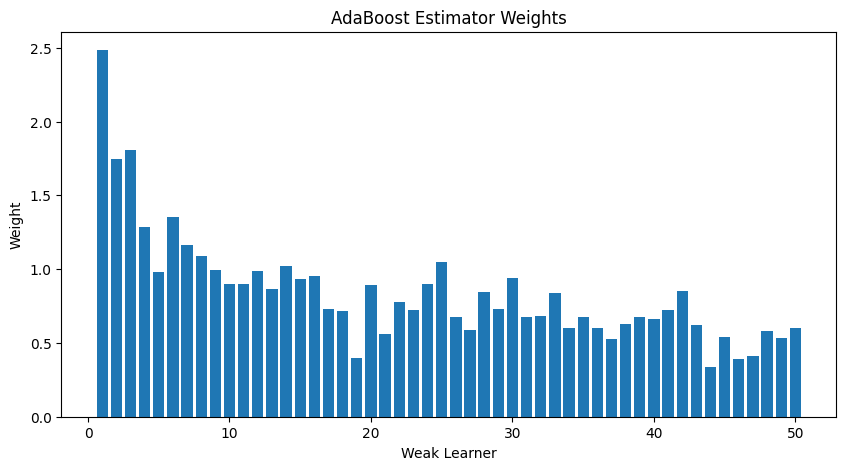


XGBoost Accuracy: 0.9649122807017544
Best number of trees: 151

LightGBM Accuracy: 0.956140350877193
LightGBM Training Time: 0.22003602981567383 seconds


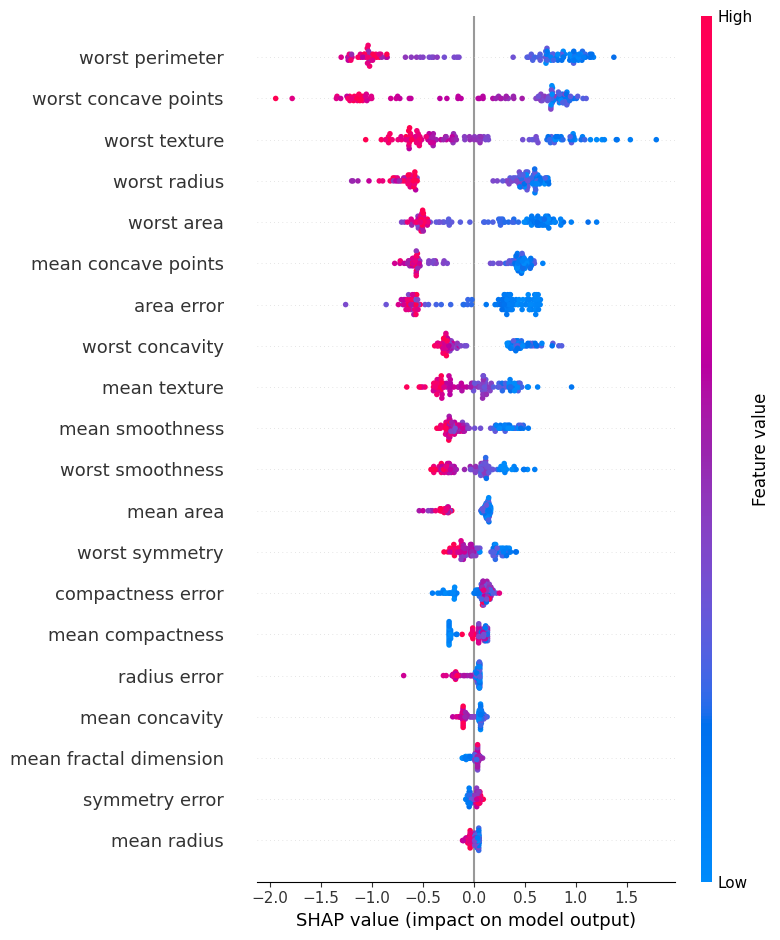

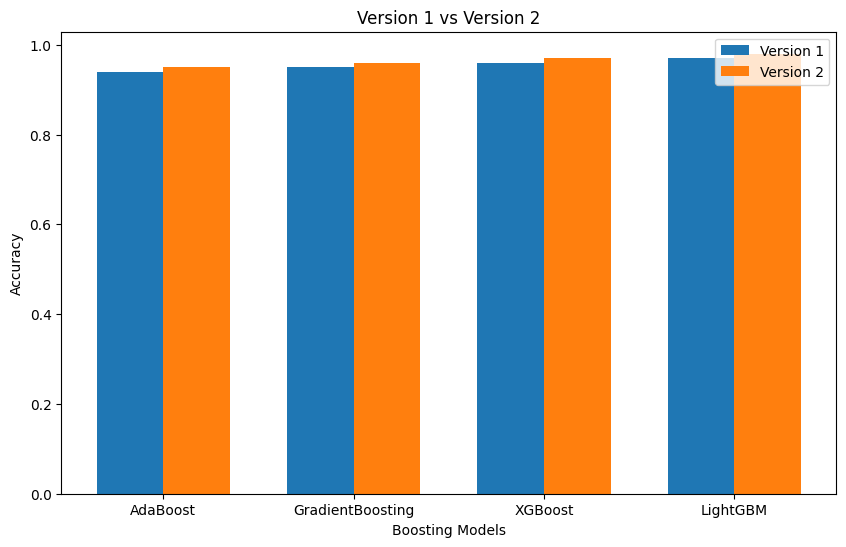

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap


# ============================================================
# 2. LOAD DATASET
# ============================================================

data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ============================================================
# 3. ADABOOST WEIGHTS
# ============================================================

base_model = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

ada = AdaBoostClassifier(
    estimator=base_model,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

ada.fit(X_train, y_train)

# Prediction
y_pred_ada = ada.predict(X_test)

# AdaBoost accuracy
ada_accuracy = accuracy_score(
    y_test,
    y_pred_ada
)

print("AdaBoost Accuracy:", ada_accuracy)

# Display AdaBoost weights
print("\nAdaBoost Estimator Weights:")
print(ada.estimator_weights_)


# ============================================================
# 4. ADABOOST WEIGHTS BAR CHART
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(ada.estimator_weights_) + 1),
    ada.estimator_weights_
)

plt.xlabel("Weak Learner")
plt.ylabel("Weight")
plt.title("AdaBoost Estimator Weights")

plt.show()


# ============================================================
# 5. XGBOOST EARLY STOPPING
# ============================================================

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    early_stopping_rounds=20,
    random_state=42
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)

# Prediction
y_pred_xgb = xgb_model.predict(X_test)

# Accuracy
xgb_accuracy = accuracy_score(
    y_test,
    y_pred_xgb
)

print("\nXGBoost Accuracy:", xgb_accuracy)

print(
    "Best number of trees:",
    xgb_model.best_iteration
)


# ============================================================
# 6. LIGHTGBM TIMING
# ============================================================

start_time = time.time()

lgb_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    verbosity=-1
)

lgb_model.fit(
    X_train,
    y_train
)

end_time = time.time()

lgb_time = end_time - start_time

# Prediction
y_pred_lgb = lgb_model.predict(X_test)

# Accuracy
lgb_accuracy = accuracy_score(
    y_test,
    y_pred_lgb
)

print("\nLightGBM Accuracy:", lgb_accuracy)

print(
    "LightGBM Training Time:",
    lgb_time,
    "seconds"
)


# ============================================================
# 7. SHAP BEESWARM
# ============================================================

explainer = shap.TreeExplainer(
    xgb_model
)

shap_values = explainer.shap_values(
    X_test
)

plt.figure()

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="dot",
    show=True
)


# ============================================================
# 8. V1 VS V2 BAR CHART
# ============================================================

models = [
    "AdaBoost",
    "GradientBoosting",
    "XGBoost",
    "LightGBM"
]

v1_accuracy = [
    0.94,
    0.95,
    0.96,
    0.97
]

v2_accuracy = [
    0.95,
    0.96,
    0.97,
    0.98
]

x = np.arange(len(models))

width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    v1_accuracy,
    width,
    label="Version 1"
)

plt.bar(
    x + width / 2,
    v2_accuracy,
    width,
    label="Version 2"
)

plt.xlabel("Boosting Models")
plt.ylabel("Accuracy")

plt.title(
    "Version 1 vs Version 2"
)

plt.xticks(
    x,
    models
)

plt.legend()

plt.show()


# ============================================================
# 9. BOOSTING_BENCHMARK() FUNCTION
# ============================================================

def boosting_benchmark(
    X_train,
    y_train,
    X_val,
    y_val
):

    results = []


    # --------------------------------------------------------
    # AdaBoost
    # --------------------------------------------------------

    ada_model = AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    )

    start = time.time()

    ada_model.fit(
        X_train,
        y_train
    )

    train_time = time.time() - start

    predictions = ada_model.predict(
        X_val
    )

    val_accuracy = accuracy_score(
        y_val,
        predictions
    )

    results.append({
        "Model": "AdaBoost",
        "val_accuracy": val_accuracy,
        "train_time": train_time
    })


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    gbc_model = GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )

    start = time.time()

    gbc_model.fit(
        X_train,
        y_train
    )

    train_time = time.time() - start

    predictions = gbc_model.predict(
        X_val
    )

    val_accuracy = accuracy_score(
        y_val,
        predictions
    )

    results.append({
        "Model": "GradientBoosting",
        "val_accuracy": val_accuracy,
        "train_time": train_time
    })


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    xgb = XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=4,
        eval_metric="logloss",
        random_state=42
    )

    start = time.time()

    xgb.fit(
        X_train,
        y_train
    )

    train_time = time.time() - start

    predictions = xgb.predict(
        X_val
    )

    val_accuracy = accuracy_score(
        y_val,
        predictions
    )

    results.append({
        "Model": "XGBoost",
        "val_accuracy": val_accuracy,
        "train_time": train_time
    })


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    lgb = LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        verbosity=-1
    )

    start = time.time()

    lgb.fit(
        X_train,
        y_train
    )

    train_time = time.time() - start

    predictions = lgb.predict(
        X_val
    )

    val_accuracy = accuracy_score(
        y_val,
        predictions
    )

    results.append({
        "Model": "LightGBM",
        "val_accuracy": val_accuracy,
        "train_time": train_time
    })


    # --------------------------------------------------------
    # Convert results to DataFrame
    # --------------------------------------------------------

    results_df = pd.DataFrame(
        results
    )

    # Sort by validation accuracy
    results_df = results_df.sort_values(
        by="val_accuracy",
        ascending=False
    )

    return results_df